In [26]:
# import zipfile

# with zipfile.ZipFile("imagewoof200.zip", 'r') as zip_ref:
#     zip_ref.extractall()

In [27]:
import os
from pathlib import Path

# Notebook'un bulunduğu klasörü ana çalışma dizini olarak algıla
BASE_DIR = Path(os.getcwd())

# Veri setinin ve test fotoğraflarının yolu dinamik olarak oluşturulur
image_path = BASE_DIR / "imagewoof200"
custom_image_path = BASE_DIR / "golden.jpg"

In [28]:
import os
def check_data(dir_path):
  for dirpath, dirnames, filenames in os.walk(dir_path):
    print(f"# of directories: {len(dirnames)} and {len(filenames)} images in '{dirpath}'.")

In [29]:
check_data(image_path)

# of directories: 2 and 3 images in 'c:\Users\bjkef\Desktop\DPJupyter\TransferLearning-ödev\imagewoof200'.
# of directories: 10 and 0 images in 'c:\Users\bjkef\Desktop\DPJupyter\TransferLearning-ödev\imagewoof200\test'.
# of directories: 0 and 48 images in 'c:\Users\bjkef\Desktop\DPJupyter\TransferLearning-ödev\imagewoof200\test\australian_terrier'.
# of directories: 0 and 48 images in 'c:\Users\bjkef\Desktop\DPJupyter\TransferLearning-ödev\imagewoof200\test\beagle'.
# of directories: 0 and 48 images in 'c:\Users\bjkef\Desktop\DPJupyter\TransferLearning-ödev\imagewoof200\test\border_terrier'.
# of directories: 0 and 48 images in 'c:\Users\bjkef\Desktop\DPJupyter\TransferLearning-ödev\imagewoof200\test\dingo'.
# of directories: 0 and 48 images in 'c:\Users\bjkef\Desktop\DPJupyter\TransferLearning-ödev\imagewoof200\test\english_foxhound'.
# of directories: 0 and 48 images in 'c:\Users\bjkef\Desktop\DPJupyter\TransferLearning-ödev\imagewoof200\test\golden_retriever'.
# of directories: 0 a

In [30]:
train_dir = image_path / "train"
test_dir = image_path / "test"

In [31]:
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

In [32]:
manual_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

In [33]:
from torch.utils.data import DataLoader

NUM_WORKERS = os.cpu_count()

def create_dataloaders(
    train_dir: str,
    test_dir: str,
    transform: transforms.Compose,
    batch_size: int,
    num_workers: int=NUM_WORKERS
):
  train_data = datasets.ImageFolder(train_dir, transform=transform)
  test_data = datasets.ImageFolder(test_dir, transform=transform)

  # Get class names
  class_names = train_data.classes

  # Turn images into data loaders
  train_dataloader = DataLoader(
      train_data,
      batch_size=batch_size,
      shuffle=True,
      num_workers=num_workers,
      pin_memory=True,
  )
  test_dataloader = DataLoader(
      test_data,
      batch_size=batch_size,
      shuffle=False,
      num_workers=num_workers,
      pin_memory=True,
  )

  return train_dataloader, test_dataloader, class_names

In [34]:
train_dataloader, test_dataloader, class_names = create_dataloaders(train_dir=train_dir,
                                                                               test_dir=test_dir,
                                                                               transform=manual_transforms,
                                                                               batch_size=32)

In [35]:
import torchvision
weights = torchvision.models.ConvNeXt_Small_Weights.DEFAULT

In [36]:
weights

ConvNeXt_Small_Weights.IMAGENET1K_V1

In [37]:
auto_transforms = weights.transforms()
auto_transforms

ImageClassification(
    crop_size=[224]
    resize_size=[230]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)

In [38]:
train_dataloader, test_dataloader, class_names = create_dataloaders(train_dir=train_dir,
                                                                               test_dir=test_dir,
                                                                               transform=auto_transforms, # perform same data transforms on our own data as the pretrained model
                                                                               batch_size=32) # set mini-batch size to 32


In [39]:
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"

In [40]:
device

'cuda'

In [41]:
model = torchvision.models.convnext_small(weights=weights).to(device)

In [42]:
from torchinfo import summary

In [43]:
# Ekran kartında (CUDA) 32'lik bir batch boyutunda sanal veri oluşturuyoruz
dummy_input = torch.randn(32, 3, 224, 224).to(device)

summary(model=model,
        input_data=dummy_input, # input_size yerine bunu kullanın
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"]
)

Layer (type (var_name))                                 Input Shape          Output Shape         Param #              Trainable
ConvNeXt (ConvNeXt)                                     [32, 3, 224, 224]    [32, 1000]           --                   True
├─Sequential (features)                                 [32, 3, 224, 224]    [32, 768, 7, 7]      --                   True
│    └─Conv2dNormActivation (0)                         [32, 3, 224, 224]    [32, 96, 56, 56]     --                   True
│    │    └─Conv2d (0)                                  [32, 3, 224, 224]    [32, 96, 56, 56]     4,704                True
│    │    └─LayerNorm2d (1)                             [32, 96, 56, 56]     [32, 96, 56, 56]     192                  True
│    └─Sequential (1)                                   [32, 96, 56, 56]     [32, 96, 56, 56]     --                   True
│    │    └─CNBlock (0)                                 [32, 96, 56, 56]     [32, 96, 56, 56]     79,296               True
│  

In [44]:
# Freeze all base layers in the "features" section of the model (the feature extractor) by setting requires_grad=False
# Özellik çıkarıcıyı dondurma
torch.manual_seed(42)
torch.cuda.manual_seed(42)
for param in model.features.parameters():
    param.requires_grad = False

output_shape = len(class_names)

# Sınıflandırıcıyı (Classifier) ConvNeXt mimarisine uygun olarak yeniden oluşturma
model.classifier = torch.nn.Sequential(
    model.classifier[0],                   # 1. Orijinal LayerNorm2d katmanını koru
    torch.nn.Flatten(start_dim=1),         # 2. Eksik olan Flatten işlemini ekle ([32, 768, 1, 1] -> [32, 768])
    torch.nn.Dropout(p=0.2, inplace=True), # 3. Dropout
    torch.nn.Linear(in_features=768, out_features=output_shape, bias=True) # 4. Yeni çıktı katmanı
).to(device)

In [45]:
dummy_input = torch.randn(32, 3, 224, 224).to(device)

summary(model=model,
        input_data=dummy_input, # input_size yerine bunu kullanın
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"]
)

Layer (type (var_name))                                 Input Shape          Output Shape         Param #              Trainable
ConvNeXt (ConvNeXt)                                     [32, 3, 224, 224]    [32, 10]             --                   Partial
├─Sequential (features)                                 [32, 3, 224, 224]    [32, 768, 7, 7]      --                   False
│    └─Conv2dNormActivation (0)                         [32, 3, 224, 224]    [32, 96, 56, 56]     --                   False
│    │    └─Conv2d (0)                                  [32, 3, 224, 224]    [32, 96, 56, 56]     (4,704)              False
│    │    └─LayerNorm2d (1)                             [32, 96, 56, 56]     [32, 96, 56, 56]     (192)                False
│    └─Sequential (1)                                   [32, 96, 56, 56]     [32, 96, 56, 56]     --                   False
│    │    └─CNBlock (0)                                 [32, 96, 56, 56]     [32, 96, 56, 56]     (79,296)             

In [46]:
from torch import nn
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [47]:
def train_step(model: torch.nn.Module,
               dataloader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               optimizer: torch.optim.Optimizer,
               device: torch.device):
    # Put model in train mode
    model.train()

    # Setup train loss and train accuracy values
    train_loss, train_acc = 0, 0

    # Loop through data loader data batches
    for batch, (X, y) in enumerate(dataloader):
        X, y = X.to(device), y.to(device)

        # 1. Forward pass
        y_pred = model(X)

        # 2. Calculate  and accumulate loss
        loss = loss_fn(y_pred, y)
        train_loss += loss.item()

        # 3. Optimizer zero grad
        optimizer.zero_grad()

        # 4. Loss backward
        loss.backward()

        # 5. Optimizer step
        optimizer.step()

        # Calculate and accumulate accuracy metrics across all batches
        y_pred_class = torch.argmax(torch.softmax(y_pred, dim=1), dim=1)
        train_acc += (y_pred_class == y).sum().item() / len(y_pred)

    # Adjust metrics to get average loss and accuracy per batch
    train_loss = train_loss / len(dataloader)
    train_acc = train_acc / len(dataloader)
    return train_loss, train_acc


def test_step(model: torch.nn.Module,
              dataloader: torch.utils.data.DataLoader,
              loss_fn: torch.nn.Module,
              device: torch.device):
    # Put model in eval mode
    model.eval()

    # Setup test loss and test accuracy values
    test_loss, test_acc = 0, 0

    # Turn on inference context manager
    with torch.inference_mode():
        # Loop through DataLoader batches
        for batch, (X, y) in enumerate(dataloader):
            X, y = X.to(device), y.to(device)
            # 1. Forward pass
            test_pred_logits = model(X)

            # 2. Calculate and accumulate loss
            loss = loss_fn(test_pred_logits, y)
            test_loss += loss.item()

            # Calculate and accumulate accuracy
            test_pred_labels = test_pred_logits.argmax(dim=1)
            test_acc += ((test_pred_labels == y).sum().item() / len(test_pred_labels))

    # Adjust metrics to get average loss and accuracy per batch
    test_loss = test_loss / len(dataloader)
    test_acc = test_acc / len(dataloader)
    return test_loss, test_acc


def train(model: torch.nn.Module,
          train_dataloader: torch.utils.data.DataLoader,
          test_dataloader: torch.utils.data.DataLoader,
          optimizer: torch.optim.Optimizer,
          device: torch.device,
          loss_fn: torch.nn.Module = nn.CrossEntropyLoss(),
          epochs: int = 5):
    # 2. Create empty results dictionary
    results = {"train_loss": [],
               "train_acc": [],
               "test_loss": [],
               "test_acc": []
               }

    # 3. Loop through training and testing steps for a number of epochs
    for epoch in range(epochs):
        train_loss, train_acc = train_step(model=model,
                                           dataloader=train_dataloader,
                                           loss_fn=loss_fn,
                                           optimizer=optimizer,
                                           device=device)
        test_loss, test_acc = test_step(model=model,
                                        dataloader=test_dataloader,
                                        loss_fn=loss_fn,
                                        device=device)

        # 4. Print out what's happening
        print(
            f"Epoch: {epoch + 1} | "
            f"train_loss: {train_loss:.4f} | "
            f"train_acc: {train_acc:.4f} | "
            f"test_loss: {test_loss:.4f} | "
            f"test_acc: {test_acc:.4f}"
        )

        # 5. Update results dictionary
        # Ensure all data is moved to CPU and converted to float for storage
        results["train_loss"].append(train_loss.item() if isinstance(train_loss, torch.Tensor) else train_loss)
        results["train_acc"].append(train_acc.item() if isinstance(train_acc, torch.Tensor) else train_acc)
        results["test_loss"].append(test_loss.item() if isinstance(test_loss, torch.Tensor) else test_loss)
        results["test_acc"].append(test_acc.item() if isinstance(test_acc, torch.Tensor) else test_acc)

    # 6. Return the filled results at the end of the epochs
    return results

In [48]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

# Start the timer
from timeit import default_timer as timer
start_time = timer()

# Setup training and save the results
results = train(model=model,
                       train_dataloader=train_dataloader,
                       test_dataloader=test_dataloader,
                       optimizer=optimizer,
                       loss_fn=loss_fn,
                       epochs=5,
                       device=device)

Epoch: 1 | train_loss: 0.6421 | train_acc: 0.9067 | test_loss: 0.1060 | test_acc: 0.9792
Epoch: 2 | train_loss: 0.1047 | train_acc: 0.9787 | test_loss: 0.0785 | test_acc: 0.9812
Epoch: 3 | train_loss: 0.0743 | train_acc: 0.9841 | test_loss: 0.0716 | test_acc: 0.9833
Epoch: 4 | train_loss: 0.0640 | train_acc: 0.9816 | test_loss: 0.0741 | test_acc: 0.9750
Epoch: 5 | train_loss: 0.0524 | train_acc: 0.9846 | test_loss: 0.0693 | test_acc: 0.9771


In [49]:
from typing import List, Tuple
import matplotlib.pyplot as plt
from PIL import Image

def transform_predict(model: torch.nn.Module,
                        image_path: str,
                        class_names: List[str],
                        image_size: Tuple[int, int] = (224, 224),
                        transform: torchvision.transforms = None,
                        device: torch.device=device):

    img = Image.open(image_path)

    if transform is not None:
        image_transform = transform
    else:
        image_transform = transforms.Compose([
            transforms.Resize(image_size),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406],
                                 std=[0.229, 0.224, 0.225]),
        ])


    model.to(device)
    model.eval()
    with torch.inference_mode():
      transformed_image = image_transform(img).unsqueeze(dim=0)
      target_image_pred = model(transformed_image.to(device))

    target_image_pred_probs = torch.softmax(target_image_pred, dim=1)
    target_image_pred_label = torch.argmax(target_image_pred_probs, dim=1)
    plt.figure()
    plt.imshow(img)
    plt.title(f"Pred: {class_names[target_image_pred_label]} | Prob: {target_image_pred_probs.max():.3f}")
    plt.axis(False)

In [51]:
custom_image_path = BASE_DIR / "imagewoof200" / "golden.jpg"

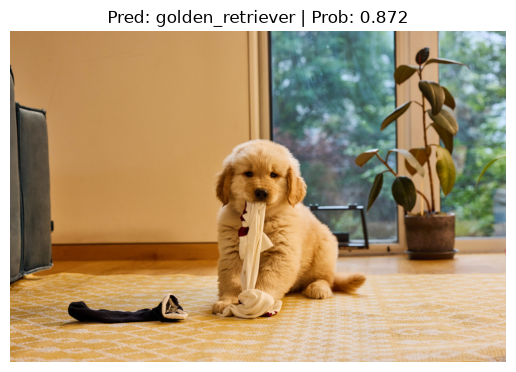

In [52]:
transform_predict(model=model,
                    image_path=custom_image_path,
                    class_names=class_names)

In [53]:
custom_image_path = BASE_DIR / "imagewoof200" / "samoyed.jpg"

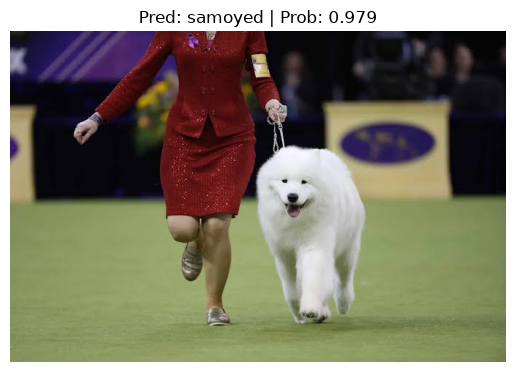

In [54]:
transform_predict(model=model,
                    image_path=custom_image_path,
                    class_names=class_names)

In [55]:
custom_image_path = BASE_DIR / "imagewoof200" / "shih tzu.jpg"

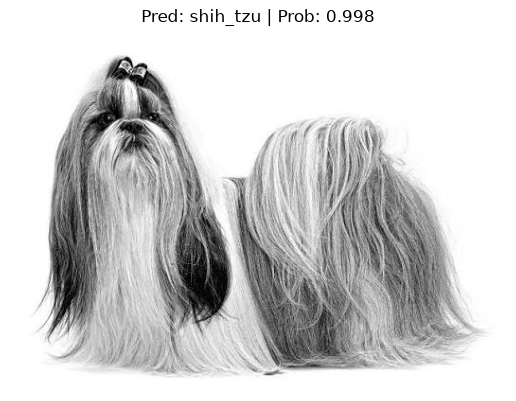

In [56]:
transform_predict(model=model,
                    image_path=custom_image_path,
                    class_names=class_names)